<a href="https://colab.research.google.com/github/benouarababdelkader-sys/pinn-structured-population-inverse/blob/main/pinn_structured_population_inverse.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [11]:
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

device = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", device)

device: cpu


In [12]:
G_TRUE, MU_TRUE = 0.5, 0.8

def u0(x):
    # Gaussian initial size distribution
    return np.exp(-((x - 0.2) ** 2) / (2 * 0.07 ** 2))

def u_exact(t, x):
    # Solution by characteristics of u_t + g u_x = -mu u
    return u0(x - G_TRUE * t) * np.exp(-MU_TRUE * t)

def make_data(times, n_x=40, noise=0.02, seed=0):
    rng = np.random.default_rng(seed)
    xs = np.linspace(0, 1, n_x)
    T, X = np.meshgrid(times, xs, indexing="ij")
    U = u_exact(T, X) + noise * rng.standard_normal(T.shape)
    return T.ravel(), X.ravel(), U.ravel()

In [13]:
class PINN(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(2, 64), nn.Tanh(),
            nn.Linear(64, 64), nn.Tanh(),
            nn.Linear(64, 64), nn.Tanh(),
            nn.Linear(64, 1),
        )
        # Unknown parameters, kept positive with softplus (start at about 0.2)
        self.raw_g = nn.Parameter(torch.tensor(-1.5))
        self.raw_mu = nn.Parameter(torch.tensor(-1.5))

    @property
    def g(self):
        return nn.functional.softplus(self.raw_g)

    @property
    def mu(self):
        return nn.functional.softplus(self.raw_mu)

    def forward(self, t, x):
        return self.net(torch.cat([t, x], dim=1))


def residual(model, t, x):
    # PDE residual: u_t + g u_x + mu u
    t.requires_grad_(True)
    x.requires_grad_(True)
    u = model(t, x)
    u_t = torch.autograd.grad(u, t, torch.ones_like(u), create_graph=True)[0]
    u_x = torch.autograd.grad(u, x, torch.ones_like(u), create_graph=True)[0]
    return u_t + model.g * u_x + model.mu * u

In [14]:
def train(times, n_x=40, noise=0.02, epochs=6000, n_col=2000, seed=0, verbose=True):
    torch.manual_seed(seed)
    t_d, x_d, u_d = make_data(times, n_x, noise, seed)
    to_t = lambda a: torch.tensor(a, dtype=torch.float32, device=device).view(-1, 1)
    t_d, x_d, u_d = to_t(t_d), to_t(x_d), to_t(u_d)

    model = PINN().to(device)
    opt = torch.optim.Adam(model.parameters(), lr=1e-3)
    hist = []
    for ep in range(epochs):
        opt.zero_grad()
        loss_data = ((model(t_d, x_d) - u_d) ** 2).mean()
        # Random collocation points where the PDE must hold
        t_c = torch.rand(n_col, 1, device=device)
        x_c = torch.rand(n_col, 1, device=device)
        loss_phys = (residual(model, t_c, x_c) ** 2).mean()
        loss = loss_data + loss_phys
        loss.backward()
        opt.step()
        hist.append((model.g.item(), model.mu.item()))
        if verbose and ep % 1000 == 0:
            print(f"epoch {ep:5d}  data {loss_data.item():.2e}  "
                  f"phys {loss_phys.item():.2e}  "
                  f"g={model.g.item():.3f}  mu={model.mu.item():.3f}")
    return model, np.array(hist)

model, hist = train(times=[0, 0.25, 0.5, 0.75, 1.0])
print("g  estimated:", round(model.g.item(), 3), " true:", G_TRUE)
print("mu estimated:", round(model.mu.item(), 3), " true:", MU_TRUE)

epoch     0  data 6.73e-02  phys 2.02e-03  g=0.202  mu=0.201
epoch  1000  data 1.11e-03  phys 5.57e-05  g=0.499  mu=0.489
epoch  2000  data 3.89e-04  phys 8.59e-06  g=0.500  mu=0.749
epoch  3000  data 3.47e-04  phys 1.11e-05  g=0.500  mu=0.790
epoch  4000  data 3.49e-04  phys 2.23e-05  g=0.500  mu=0.793
epoch  5000  data 3.47e-04  phys 2.65e-05  g=0.500  mu=0.794
g  estimated: 0.5  true: 0.5
mu estimated: 0.795  true: 0.8


In [15]:
import pandas as pd

def run(times, noise, seed, epochs=3000):
    model, _ = train(times=times, noise=noise, seed=seed,
                     epochs=epochs, n_col=1000, verbose=False)
    return model.g.item(), model.mu.item()

time_sets = {
    1: [0.5],
    2: [0.25, 0.75],
    3: [0.0, 0.5, 1.0],
    5: [0.0, 0.25, 0.5, 0.75, 1.0],
    9: list(np.linspace(0, 1, 9)),
}
noise_levels = [0.0, 0.02, 0.05, 0.10]
seeds = [0, 1, 2]

rows = []
# Experiment A: effect of noise (5 observation times)
for noise in noise_levels:
    for s in seeds:
        g, mu = run(time_sets[5], noise, s)
        rows.append(dict(exp="noise", noise=noise, n_times=5, seed=s, g=g, mu=mu))
# Experiment B: effect of the number of observation times (noise 0.02)
for n, ts in time_sets.items():
    for s in seeds:
        g, mu = run(ts, 0.02, s)
        rows.append(dict(exp="times", noise=0.02, n_times=n, seed=s, g=g, mu=mu))

res = pd.DataFrame(rows)
res["err_g"] = (res.g - G_TRUE).abs() / G_TRUE
res["err_mu"] = (res.mu - MU_TRUE).abs() / MU_TRUE
print(res.groupby(["exp", "noise", "n_times"])[["g", "mu", "err_g", "err_mu"]]
         .agg(["mean", "std"]).round(3))

                         g            mu         err_g        err_mu       
                      mean    std   mean    std   mean    std   mean    std
exp   noise n_times                                                        
noise 0.00  5        0.500  0.000  0.792  0.003  0.000  0.000  0.010  0.004
      0.02  5        0.500  0.000  0.804  0.012  0.001  0.000  0.013  0.004
      0.05  5        0.501  0.001  0.819  0.029  0.002  0.001  0.036  0.015
      0.10  5        0.503  0.001  0.844  0.054  0.005  0.001  0.071  0.041
times 0.02  1        0.188  0.017  0.165  0.010  0.624  0.033  0.794  0.012
            2        0.501  0.004  0.761  0.051  0.007  0.003  0.049  0.064
            3        0.500  0.003  0.796  0.021  0.004  0.002  0.018  0.015
            5        0.500  0.000  0.804  0.012  0.001  0.000  0.013  0.004
            9        0.501  0.002  0.796  0.006  0.003  0.002  0.005  0.007


In [17]:
timing_sets = {
    "early":  [0.0, 0.25],
    "middle": [0.4, 0.6],
    "late":   [0.75, 1.0],
    "spread": [0.0, 1.0],
}
rows_t = []
for name, ts in timing_sets.items():
    for s in seeds:
        g, mu = run(ts, 0.02, s)
        rows_t.append(dict(timing=name, seed=s, g=g, mu=mu))

res_t = pd.DataFrame(rows_t)
res_t["err_g"] = (res_t.g - G_TRUE).abs() / G_TRUE
res_t["err_mu"] = (res_t.mu - MU_TRUE).abs() / MU_TRUE
print(res_t.groupby("timing")[["g", "mu", "err_g", "err_mu"]].agg(["mean", "std"]).round(3))

            g            mu         err_g        err_mu       
         mean    std   mean    std   mean    std   mean    std
timing                                                        
early   0.503  0.004  0.685  0.029  0.008  0.006  0.144  0.036
late    0.508  0.007  0.437  0.100  0.016  0.013  0.454  0.124
middle  0.492  0.006  0.466  0.044  0.017  0.011  0.417  0.055
spread  0.502  0.001  0.798  0.024  0.004  0.002  0.020  0.016


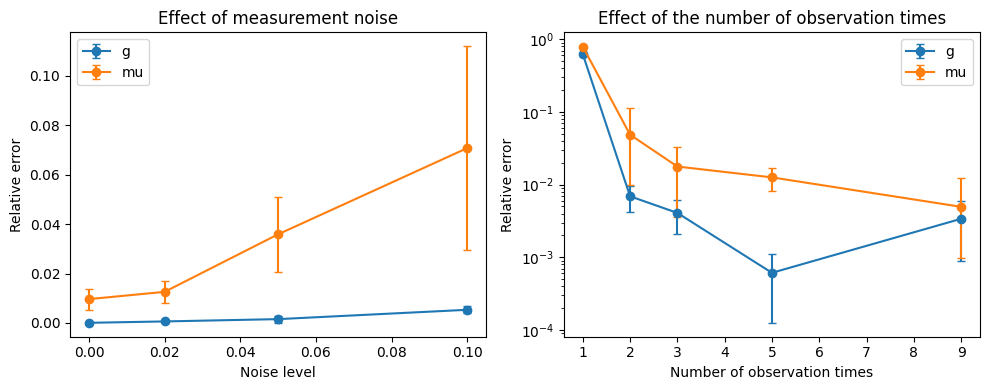

In [18]:
fig, ax = plt.subplots(1, 2, figsize=(10, 4))

a = res[res.exp == "noise"].groupby("noise")[["err_g", "err_mu"]].agg(["mean", "std"])
for p, lab in [("err_g", "g"), ("err_mu", "mu")]:
    ax[0].errorbar(a.index, a[p]["mean"], yerr=a[p]["std"], marker="o", capsize=3, label=lab)
ax[0].set_xlabel("Noise level"); ax[0].set_ylabel("Relative error"); ax[0].legend()
ax[0].set_title("Effect of measurement noise")

b = res[res.exp == "times"].groupby("n_times")[["err_g", "err_mu"]].agg(["mean", "std"])
for p, lab in [("err_g", "g"), ("err_mu", "mu")]:
    m, sd = b[p]["mean"].values, b[p]["std"].values
    lower = np.minimum(sd, 0.8 * m)   # keeps the bar visible on a log scale
    ax[1].errorbar(b.index, m, yerr=[lower, sd], marker="o", capsize=3, label=lab)
ax[1].set_xlabel("Number of observation times"); ax[1].set_ylabel("Relative error")
ax[1].set_yscale("log"); ax[1].legend()
ax[1].set_title("Effect of the number of observation times")

plt.tight_layout()
plt.savefig("noise_and_times.png", dpi=150, bbox_inches="tight")
plt.show()

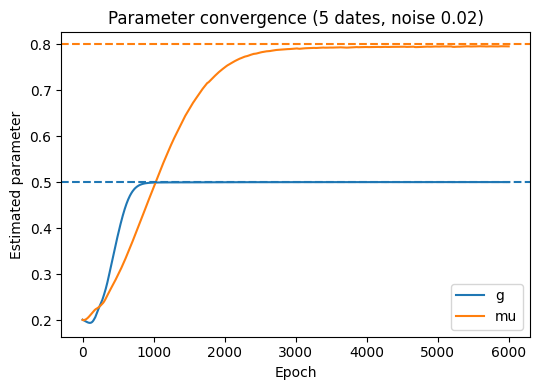

In [19]:
plt.figure(figsize=(5.5, 4))
plt.plot(hist[:, 0], label="g")
plt.plot(hist[:, 1], label="mu")
plt.axhline(G_TRUE, ls="--", c="C0")
plt.axhline(MU_TRUE, ls="--", c="C1")
plt.xlabel("Epoch")
plt.ylabel("Estimated parameter")
plt.title("Parameter convergence (5 dates, noise 0.02)")
plt.legend()
plt.tight_layout()
plt.savefig("convergence.png", dpi=150, bbox_inches="tight")
plt.show()

In [20]:
gap_sets = {
    "gap0.5 start": [0.0, 0.5],
    "gap0.5 middle": [0.25, 0.75],
    "gap0.5 end": [0.5, 1.0],
}
rows_g = []
for name, ts in gap_sets.items():
    for s in seeds:
        g, mu = run(ts, 0.02, s)
        rows_g.append(dict(timing=name, seed=s, g=g, mu=mu))

res_g = pd.DataFrame(rows_g)
res_g["err_g"] = (res_g.g - G_TRUE).abs() / G_TRUE
res_g["err_mu"] = (res_g.mu - MU_TRUE).abs() / MU_TRUE
print(res_g.groupby("timing")[["g", "mu", "err_g", "err_mu"]].agg(["mean", "std"]).round(3))

                   g            mu         err_g        err_mu       
                mean    std   mean    std   mean    std   mean    std
timing                                                               
gap0.5 end     0.499  0.007  0.734  0.045  0.011  0.006  0.082  0.056
gap0.5 middle  0.501  0.004  0.761  0.051  0.007  0.003  0.049  0.064
gap0.5 start   0.499  0.003  0.788  0.018  0.005  0.002  0.019  0.018


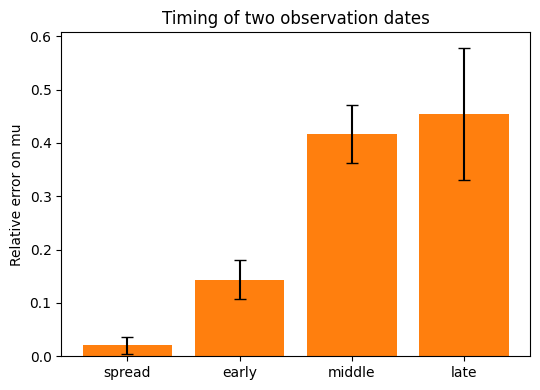

In [21]:
fig, ax = plt.subplots(figsize=(5.5, 4))
order = ["spread", "early", "middle", "late"]
t = res_t.groupby("timing")["err_mu"].agg(["mean", "std"]).loc[order]
ax.bar(order, t["mean"], yerr=t["std"], capsize=4, color="C1")
ax.set_ylabel("Relative error on mu")
ax.set_title("Timing of two observation dates")
plt.tight_layout()
plt.savefig("timing.png", dpi=150, bbox_inches="tight")
plt.show()

In [22]:
from google.colab import files
for f in ["noise_and_times.png", "timing.png", "convergence.png"]:
    files.download(f)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>